<a href="https://colab.research.google.com/github/salman-zahid-11/collab-project/blob/main/SMS_Spam_SVM_By_SALMAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS Spam Classification using SVM
Dataset: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset?resource=download

In [1]:
# Install (if needed)
!pip -q install wordcloud nltk scikit-learn


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import re, string, nltk
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,classification_report,
confusion_matrix,ConfusionMatrixDisplay,
precision_score,recall_score,f1_score,roc_curve,auc)

nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


## Upload dataset (`spam.csv`) downloaded from Kaggle.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving SMS.csv to SMS.csv


In [4]:
df = pd.read_csv("SMS.csv", encoding="latin-1")

df = df[['v1', 'v2']]

df.columns = ['label', 'message']

In [5]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:",df.duplicated().sum())
print(df['label'].value_counts())


(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


## Exploratory Data Analysis

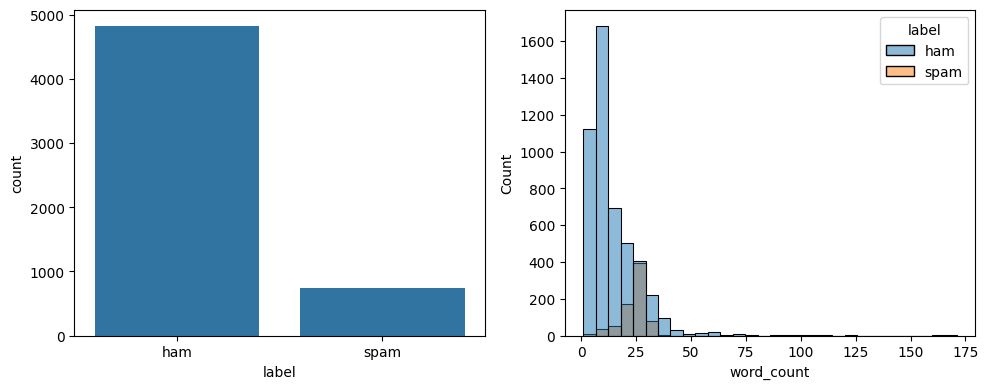

In [6]:
df['char_count']=df['message'].str.len()
df['word_count']=df['message'].str.split().str.len()

fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.countplot(data=df,x='label',ax=ax[0])
sns.histplot(data=df,x='word_count',hue='label',bins=30,ax=ax[1])
plt.tight_layout()
plt.show()




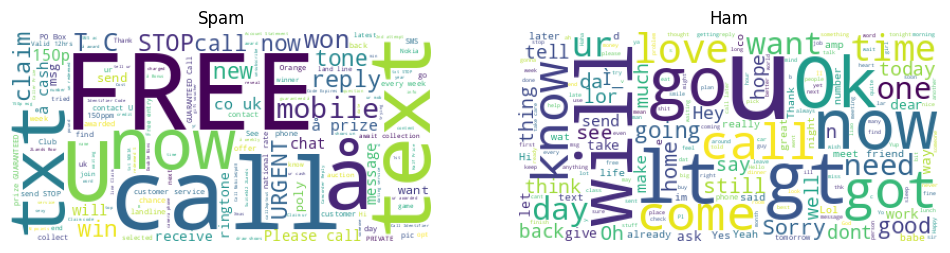

In [7]:
spam=' '.join(df[df.label=='spam'].message)
ham=' '.join(df[df.label=='ham'].message)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(WordCloud(background_color='white').generate(spam))
plt.axis('off'); plt.title("Spam")
plt.subplot(1,2,2)
plt.imshow(WordCloud(background_color='white').generate(ham))
plt.axis('off'); plt.title("Ham")
plt.show()


## Preprocessing

In [8]:
# Load the list of English stopwords (e.g., "the", "is", "and")
stop_words = set(stopwords.words('english'))

# Create a WordNet lemmatizer object to convert words to their base form
lemm = WordNetLemmatizer()

# Define a function to clean and preprocess SMS text
def clean_text(text):

    # Convert all characters to lowercase
    text = text.lower()

    # Remove URLs (e.g., http://example.com or www.example.com)
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove email addresses (e.g., abc@gmail.com)
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove all numeric digits from the text
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation marks such as !, ?, ., ,, :, etc.
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Split the sentence into words,
    # remove stopwords,
    # and convert each word to its base (lemma) form
    tokens = [
        lemm.lemmatize(word)
        for word in text.split()
        if word not in stop_words
    ]

    # Join the cleaned words back into a single string
    return ' '.join(tokens)

# Remove duplicate SMS messages from the dataset
df = df.drop_duplicates()

# Apply the clean_text() function to every message
# and store the cleaned text in a new column named 'clean_message'
df['clean_message'] = df['message'].apply(clean_text)

# Convert categorical labels into numerical values
# ham  -> 0
# spam -> 1
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

# Display the first five rows of the processed dataset
df.head()

,label,message,char_count,word_count,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",111,20,go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,29,6,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,free entry wkly comp win fa cup final tkts st ...
3,0,U dun say so early hor... U c already then say...,49,11,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13,nah dont think go usf life around though


## Feature Engineering (new)
`clean_text()` removes digits, URLs and punctuation, but those are exactly the signals spam relies on
(phone numbers, `£` prizes, "!!!", ALL CAPS, links). So we engineer **hand-crafted features from the raw message**
and feed them to the model alongside TF-IDF.

label,ham,spam
char_count,70.459,137.891
word_count,14.135,23.681
avg_word_len,5.054,5.954
digit_count,0.290,15.447
digit_ratio,0.004,0.114
upper_ratio,0.057,0.110
all_caps_words,0.381,2.000
exclaim_count,0.175,0.694
special_count,3.859,6.058
has_url,0.003,0.178


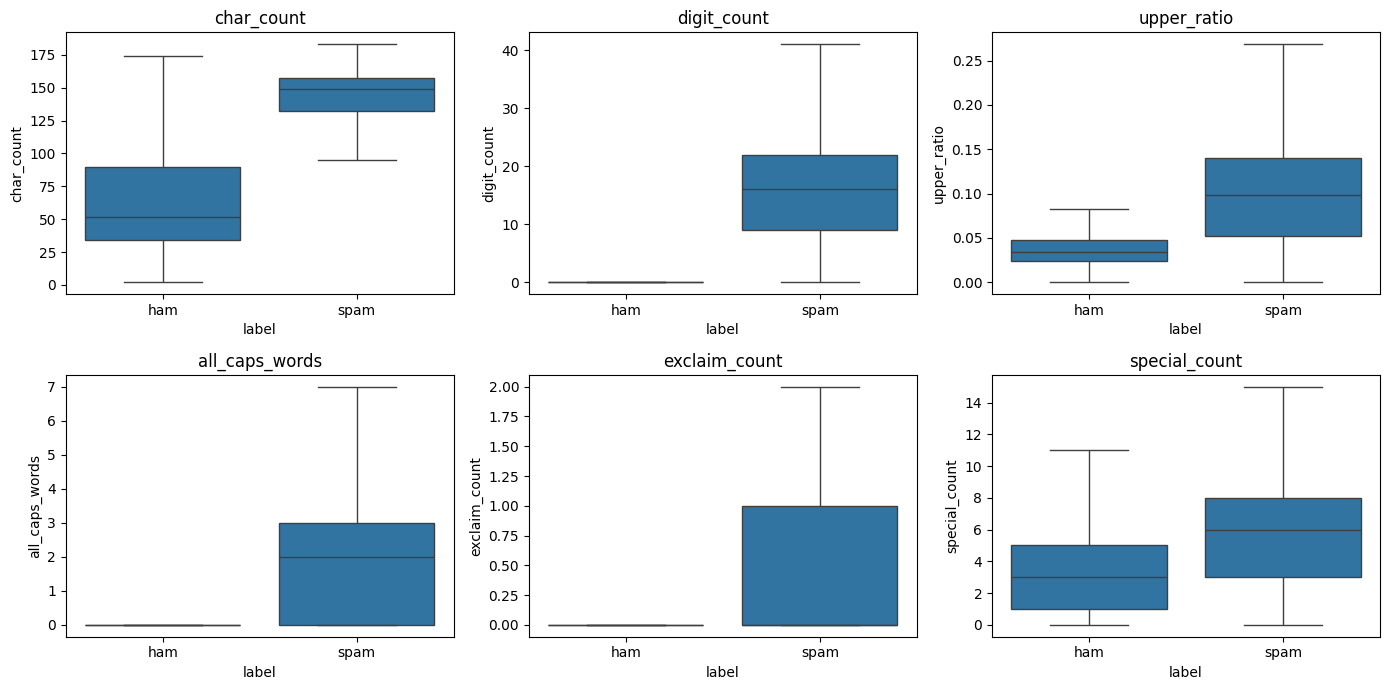

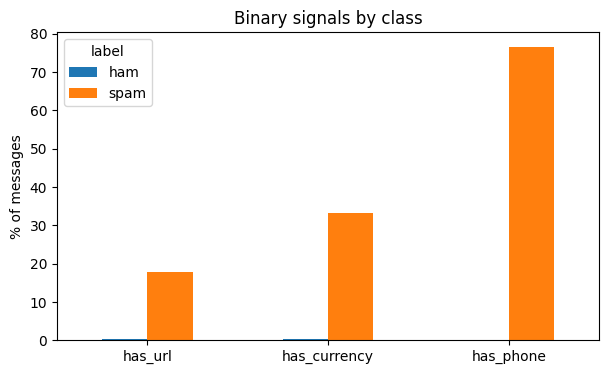

In [9]:
META_COLS = ['char_count', 'word_count', 'avg_word_len', 'digit_count', 'digit_ratio',
             'upper_ratio', 'all_caps_words', 'exclaim_count', 'special_count',
             'has_url', 'has_currency', 'has_phone']

def extract_meta_features(messages):
    """Hand-crafted numeric features computed from the RAW message text."""
    s = pd.Series(messages).astype(str).reset_index(drop=True)
    n_chars = s.str.len().clip(lower=1)
    n_words = s.str.split().str.len().clip(lower=1)
    feats = pd.DataFrame({
        'char_count'    : s.str.len(),
        'word_count'    : s.str.split().str.len(),
        'avg_word_len'  : n_chars / n_words,
        'digit_count'   : s.str.count(r'\d'),
        'digit_ratio'   : s.str.count(r'\d') / n_chars,
        'upper_ratio'   : s.str.count(r'[A-Z]') / n_chars,
        'all_caps_words': s.str.count(r'\b[A-Z]{2,}\b'),
        'exclaim_count' : s.str.count('!'),
        'special_count' : s.str.count(r'[^\w\s]'),
        'has_url'       : s.str.contains(r'http|www\.|\.com|\.co\.uk', case=False).astype(int),
        'has_currency'  : s.str.contains(r'[£$€]').astype(int),
        'has_phone'     : s.str.contains(r'\d{5,}').astype(int),   # phone numbers / short codes
    })
    return feats[META_COLS].values

meta_df = pd.DataFrame(extract_meta_features(df['message']), columns=META_COLS, index=df.index)
meta_df['label'] = df['label'].map({0: 'ham', 1: 'spam'})

# Average value of each feature per class
display(meta_df.groupby('label').mean().T.round(3))

# Distribution of the most discriminative features
plot_cols = ['char_count', 'digit_count', 'upper_ratio', 'all_caps_words', 'exclaim_count', 'special_count']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), plot_cols):
    sns.boxplot(data=meta_df, x='label', y=col, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Share of messages containing each binary signal
binary_cols = ['has_url', 'has_currency', 'has_phone']
(meta_df.groupby('label')[binary_cols].mean() * 100).T.plot(kind='bar', figsize=(7, 4))
plt.ylabel('% of messages'); plt.title('Binary signals by class'); plt.xticks(rotation=0)
plt.show()

## Train/Test Split

In [10]:
from sklearn.model_selection import train_test_split

X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)


(4135,)
(1034,)


## SVM Model

In [11]:
pipeline=Pipeline([
('tfidf',TfidfVectorizer(max_features=5000,ngram_range=(1,2))),
('svm',LinearSVC())
])

pipeline.fit(X_train,y_train)
pred=pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test,pred))
print("Precision:",precision_score(y_test,pred))
print("Recall:",recall_score(y_test,pred))
print("F1:",f1_score(y_test,pred))
print(classification_report(y_test,pred))




Accuracy: 0.9845261121856866
Precision: 0.9831932773109243
Recall: 0.8931297709923665
F1: 0.936
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       903
           1       0.98      0.89      0.94       131

    accuracy                           0.98      1034
   macro avg       0.98      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034



## Hyperparameter Tuning

In [12]:
param_grid={
'svm__C':[0.1,1,10]
}
grid=GridSearchCV(pipeline,param_grid,cv=5,n_jobs=-1)
grid.fit(X_train,y_train)

print("Best Parameters:",grid.best_params_)
print("Best CV Score:",grid.best_score_)


Best Parameters: {'svm__C': 1}
Best CV Score: 0.9787182587666263


## Cross Validation

In [13]:
scores=cross_val_score(grid.best_estimator_,df['clean_message'],df['label'],cv=5)
print(scores)
print("Mean Accuracy:",scores.mean())


[0.98162476 0.9787234  0.98065764 0.98162476 0.97483059]
Mean Accuracy: 0.9794922302883003


## Enhanced Model: Word + Character TF-IDF + Meta Features (new)
Three feature groups are combined with a `ColumnTransformer`:
1. **Word TF-IDF** (1-2 grams) on the cleaned text
2. **Character TF-IDF** (2-5 grams) on the raw text, which captures things like `£`, `!!`, `txt`, `www`
3. **Meta features** (log-scaled + `MaxAbsScaler`)

We also tune `class_weight` (spam is only ~13% of the data) and optimise **F1** instead of accuracy.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (ConfusionMatrixDisplay, precision_recall_curve,
                             average_precision_score, roc_auc_score)

def build_pipeline(clf):
    features = ColumnTransformer([
        ('word', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True), 'clean_message'),
        ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), max_features=10000,
                                 sublinear_tf=True), 'message'),
        ('meta', Pipeline([('extract', FunctionTransformer(extract_meta_features)),
                           ('log',     FunctionTransformer(np.log1p)),
                           ('scale',   MaxAbsScaler())]), 'message'),
    ])
    return Pipeline([('features', features), ('clf', clf)])

# Reuse the exact same train/test rows as the baseline model
X_train_df = df.loc[X_train.index, ['message', 'clean_message']]
X_test_df  = df.loc[X_test.index,  ['message', 'clean_message']]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid_enh = {
    'clf__C': [0.1, 0.5, 1, 5, 10],
    'clf__class_weight': [None, 'balanced'],
}
grid_enh = GridSearchCV(build_pipeline(LinearSVC(max_iter=10000)), param_grid_enh,
                        cv=skf, scoring='f1', n_jobs=-1)
grid_enh.fit(X_train_df, y_train)

print("Best Parameters:", grid_enh.best_params_)
print("Best CV F1     :", round(grid_enh.best_score_, 4))

best_svm = grid_enh.best_estimator_
pred_enh = best_svm.predict(X_test_df)

# Baseline vs enhanced on the same held-out test set
def scores(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred)}

comparison = pd.DataFrame({'Baseline (word TF-IDF)': scores(y_test, pred),
                           'Enhanced (word+char+meta)': scores(y_test, pred_enh)}).T
display(comparison.round(4))
print(classification_report(y_test, pred_enh, target_names=['ham', 'spam']))

Best Parameters: {'clf__C': 0.5, 'clf__class_weight': 'balanced'}
Best CV F1     : 0.9573


,Accuracy,Precision,Recall,F1
Baseline (word TF-IDF),0.9845,0.9832,0.8931,0.9360
Enhanced (word+char+meta),0.9903,0.9840,0.9389,0.9609


              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.98      0.94      0.96       131

    accuracy                           0.99      1034
   macro avg       0.99      0.97      0.98      1034
weighted avg       0.99      0.99      0.99      1034



## Model Comparison (new)
Same features, different classifiers, evaluated with stratified 5-fold CV on the training set.

,accuracy,precision,recall,f1
LinearSVC,0.9894,0.9709,0.9444,0.9573
LogisticRegression,0.9889,0.9671,0.9444,0.9554
ComplementNB,0.9874,0.9683,0.9310,0.9492


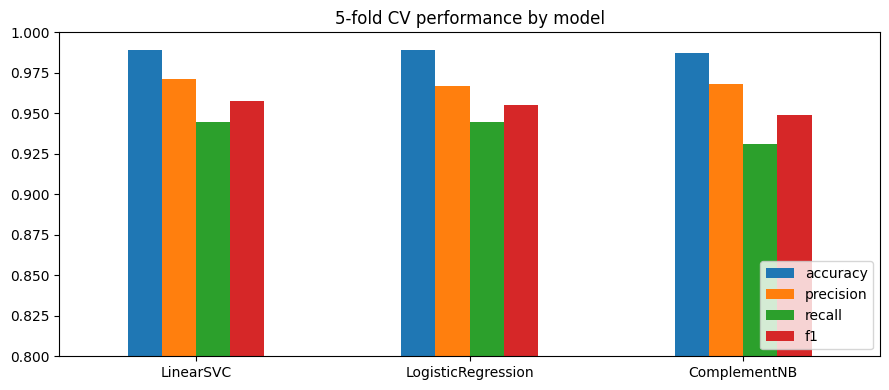

In [15]:
best_C  = grid_enh.best_params_['clf__C']
best_cw = grid_enh.best_params_['clf__class_weight']

models = {
    'LinearSVC'          : LinearSVC(C=best_C, class_weight=best_cw, max_iter=10000),
    'LogisticRegression' : LogisticRegression(C=10, class_weight='balanced', max_iter=2000),
    'ComplementNB'       : ComplementNB(),
}

rows = {}
for name, clf in models.items():
    cv = cross_validate(build_pipeline(clf), X_train_df, y_train, cv=skf,
                        scoring=['accuracy', 'precision', 'recall', 'f1'], n_jobs=-1)
    rows[name] = {m: cv[f'test_{m}'].mean() for m in ['accuracy', 'precision', 'recall', 'f1']}

cmp_df = pd.DataFrame(rows).T.round(4)
display(cmp_df)

cmp_df.plot(kind='bar', figsize=(9, 4), ylim=(0.8, 1.0))
plt.title('5-fold CV performance by model'); plt.xticks(rotation=0); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

## Detailed Evaluation (new)
Confusion matrix, ROC curve and Precision-Recall curve. The PR curve is the more honest view for an imbalanced problem.

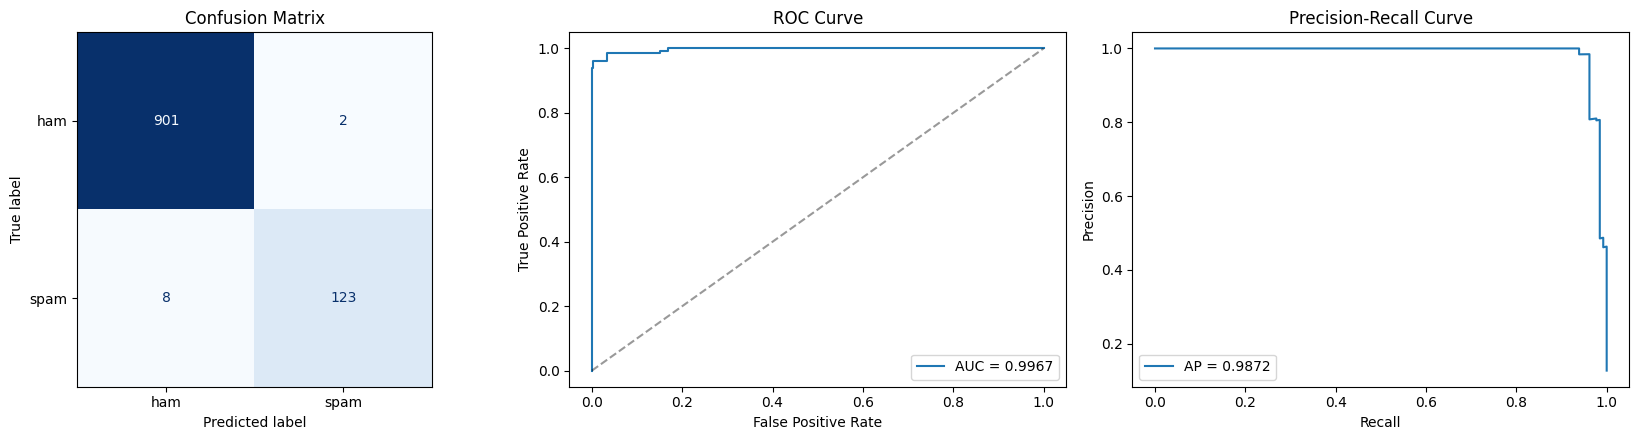

In [16]:
scores_test = best_svm.decision_function(X_test_df)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, pred_enh, display_labels=['ham', 'spam'],
                                        cmap='Blues', ax=ax[0], colorbar=False)
ax[0].set_title('Confusion Matrix')

# ROC curve
fpr, tpr, _ = roc_curve(y_test, scores_test)
ax[1].plot(fpr, tpr, label=f'AUC = {auc(fpr, tpr):.4f}')
ax[1].plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax[1].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC Curve')
ax[1].legend(loc='lower right')

# Precision-Recall curve
prec, rec, _ = precision_recall_curve(y_test, scores_test)
ax[2].plot(rec, prec, label=f'AP = {average_precision_score(y_test, scores_test):.4f}')
ax[2].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall Curve')
ax[2].legend(loc='lower left')

plt.tight_layout(); plt.show()

## Error Analysis (new)
Which messages does the model get wrong? A false positive means a legitimate message was flagged as spam
(usually the costlier mistake); a false negative means spam slipped through.

In [17]:
errors = X_test_df[['message']].copy()
errors['actual']    = y_test.map({0: 'ham', 1: 'spam'})
errors['predicted'] = pd.Series(pred_enh, index=y_test.index).map({0: 'ham', 1: 'spam'})
errors['score']     = scores_test

pd.set_option('display.max_colwidth', 150)
fp = errors[(errors.actual == 'ham')  & (errors.predicted == 'spam')]
fn = errors[(errors.actual == 'spam') & (errors.predicted == 'ham')]

print(f"False positives (ham flagged as spam): {len(fp)}")
display(fp.sort_values('score', ascending=False).head(10))
print(f"False negatives (spam missed): {len(fn)}")
display(fn.sort_values('score').head(10))

False positives (ham flagged as spam): 2


,message,actual,predicted,score
1289,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May",ham,spam,0.074051
3042,Your bill at 3 is å£33.65 so thats not bad!,ham,spam,0.024644


False negatives (spam missed): 8


,message,actual,predicted,score
5449,"Latest News! Police station toilet stolen, cops have nothing to go on!",spam,ham,-0.945621
1874,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,spam,ham,-0.922368
4819,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,spam,ham,-0.581113
4142,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)",spam,ham,-0.577130
2769,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner,spam,ham,-0.576592
2401,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(...,spam,ham,-0.117940
3528,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're se...",spam,ham,-0.065952
671,SMS. ac sun0819 posts HELLO:\You seem cool,spam,ham,-0.048355


## Most Informative Features (new)
The coefficients of the linear SVM show what pushes a message towards spam or ham.

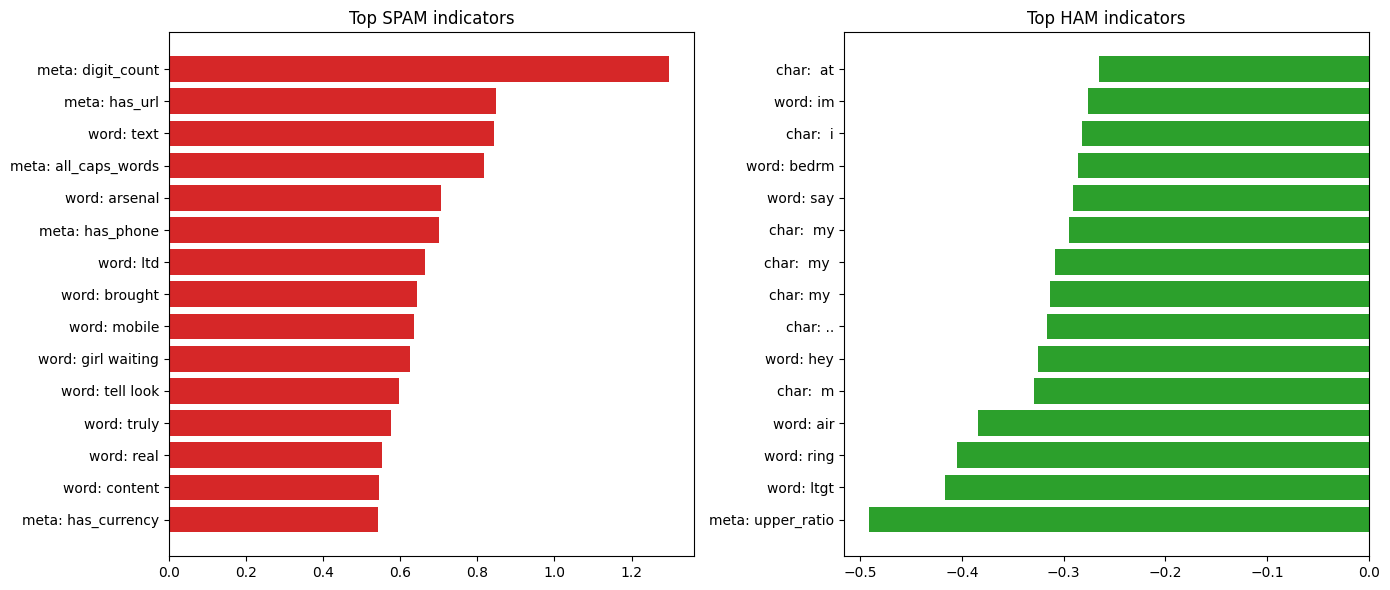

In [18]:
feat_union = best_svm.named_steps['features']
feature_names = np.concatenate([
    ['word: ' + f for f in feat_union.named_transformers_['word'].get_feature_names_out()],
    ['char: ' + f for f in feat_union.named_transformers_['char'].get_feature_names_out()],
    ['meta: ' + f for f in META_COLS],
])
coefs = best_svm.named_steps['clf'].coef_.ravel()
assert len(feature_names) == len(coefs)

top_n = 15
order = np.argsort(coefs)
top_spam, top_ham = order[-top_n:], order[:top_n]

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].barh(feature_names[top_spam], coefs[top_spam], color='tab:red');  ax[0].set_title('Top SPAM indicators')
ax[1].barh(feature_names[top_ham],  coefs[top_ham],  color='tab:green'); ax[1].set_title('Top HAM indicators')
plt.tight_layout(); plt.show()

## Final Model with Spam Probability (new)
`LinearSVC` only returns a margin, not a probability. Wrapping it in `CalibratedClassifierCV` gives a calibrated
**spam probability**, which lets us choose our own decision threshold.

In [19]:
final_model = build_pipeline(
    CalibratedClassifierCV(LinearSVC(C=best_C, class_weight=best_cw, max_iter=10000), cv=5)
)
final_model.fit(X_train_df, y_train)

proba_test = final_model.predict_proba(X_test_df)[:, 1]
print("ROC-AUC (calibrated):", round(roc_auc_score(y_test, proba_test), 4))

# Effect of the decision threshold
thr_rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (proba_test >= t).astype(int)
    thr_rows.append({'threshold': t, 'precision': precision_score(y_test, p),
                     'recall': recall_score(y_test, p), 'f1': f1_score(y_test, p)})
display(pd.DataFrame(thr_rows).set_index('threshold').round(4))

ROC-AUC (calibrated): 0.9971


,precision,recall,f1
threshold,,,
0.3,0.9841,0.9466,0.9650
0.4,0.9840,0.9389,0.9609
0.5,1.0000,0.9313,0.9644
0.6,1.0000,0.9237,0.9603
0.7,1.0000,0.9084,0.9520
0.8,1.0000,0.8931,0.9435


## Prediction Function (updated)
Returns the verdict, the spam probability and the suspicious signals found in the message.

In [20]:
def predict_sms(text, threshold=0.5, verbose=True):
    row = pd.DataFrame({'message': [text], 'clean_message': [clean_text(text)]})
    prob = final_model.predict_proba(row)[0, 1]
    label = 'Spam' if prob >= threshold else 'Ham'

    meta = dict(zip(META_COLS, extract_meta_features([text])[0]))
    signals = []
    if meta['has_url']:         signals.append('contains a link')
    if meta['has_currency']:    signals.append('mentions money')
    if meta['has_phone']:       signals.append('contains a phone number / short code')
    if meta['all_caps_words']:  signals.append(f"{int(meta['all_caps_words'])} ALL-CAPS word(s)")
    if meta['exclaim_count']:   signals.append(f"{int(meta['exclaim_count'])} exclamation mark(s)")

    if verbose:
        print(f"{label}  (spam probability: {prob:.1%})")
        print("Signals:", ', '.join(signals) if signals else 'none')
        print(f"Message: {text}\n")
    return label, prob

tests = [
    "Congratulations! You have won a free iPhone. Click here now.",
    "Hi, are we meeting tomorrow at 3 PM?",
    "URGENT! Your account has been selected for a £1000 prize. Call 09061701461 to claim.",
    "Can you pick up milk on your way home?",
    "FREE entry in a weekly competition! Text WIN to 80086 now!",
]
for t in tests:
    predict_sms(t)

Ham  (spam probability: 10.9%)
Signals: 1 exclamation mark(s)
Message: Congratulations! You have won a free iPhone. Click here now.

Ham  (spam probability: 0.5%)
Signals: 1 ALL-CAPS word(s)
Message: Hi, are we meeting tomorrow at 3 PM?

Spam  (spam probability: 99.9%)
Signals: mentions money, contains a phone number / short code, 1 ALL-CAPS word(s), 1 exclamation mark(s)
Message: URGENT! Your account has been selected for a £1000 prize. Call 09061701461 to claim.

Ham  (spam probability: 0.2%)
Signals: none
Message: Can you pick up milk on your way home?

Spam  (spam probability: 99.6%)
Signals: contains a phone number / short code, 2 ALL-CAPS word(s), 2 exclamation mark(s)
Message: FREE entry in a weekly competition! Text WIN to 80086 now!



## Batch Prediction & Save Model (new)

In [21]:
import joblib

def predict_many(messages, threshold=0.5):
    """Classify a list of messages and return a DataFrame sorted by spam probability."""
    frame = pd.DataFrame({'message': messages, 'clean_message': [clean_text(m) for m in messages]})
    prob = final_model.predict_proba(frame)[:, 1]
    out = pd.DataFrame({'message': messages, 'spam_probability': prob.round(4),
                        'prediction': np.where(prob >= threshold, 'Spam', 'Ham')})
    return out.sort_values('spam_probability', ascending=False).reset_index(drop=True)

display(predict_many(tests))

# Save the full pipeline (vectorizers + scaler + calibrated SVM).
# Note: extract_meta_features and clean_text must be defined when you joblib.load() it again.
joblib.dump(final_model, 'sms_spam_svm.joblib')
print("Saved to sms_spam_svm.joblib")

# In Colab, uncomment to download:
# from google.colab import files; files.download('sms_spam_svm.joblib')

,message,spam_probability,prediction
0,URGENT! Your account has been selected for a £1000 prize. Call 09061701461 to claim.,0.9993,Spam
1,FREE entry in a weekly competition! Text WIN to 80086 now!,0.9959,Spam
2,Congratulations! You have won a free iPhone. Click here now.,0.1094,Ham
3,"Hi, are we meeting tomorrow at 3 PM?",0.0047,Ham
4,Can you pick up milk on your way home?,0.0021,Ham


Saved to sms_spam_svm.joblib
